In [1]:
import numpy as np
from sklearn.metrics import f1_score, roc_auc_score
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# 1. Device & Seed setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
classes = ['CD', 'HYP', 'MI', 'NORM', 'STTC']

# 2. Saved .npy files load karo
X_train = np.load('processed_data/X_train.npy')
y_train = np.load('processed_data/y_train.npy')
X_val = np.load('processed_data/X_val.npy')
y_val = np.load('processed_data/y_val.npy')
X_test = np.load('processed_data/X_test.npy')
y_test = np.load('processed_data/y_test.npy')

# 3. Sirf X_train se Mean & Std nikaal kar teeno ko scale karo
mean = X_train.mean(axis=(0, 1), keepdims=True)
std = X_train.std(axis=(0, 1), keepdims=True) + 1e-8

X_train = np.transpose((X_train - mean) / std, (0, 2, 1))
X_val = np.transpose((X_val - mean) / std, (0, 2, 1))
X_test = np.transpose((X_test - mean) / std, (0, 2, 1))

# 4. DataLoaders taiyaar karo
BATCH_SIZE = 64
train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.float32),
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
)
val_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_val, dtype=torch.float32),
        torch.tensor(y_val, dtype=torch.float32),
    ),
    batch_size=BATCH_SIZE,
    shuffle=False,
)
test_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_test, dtype=torch.float32),
        torch.tensor(y_test, dtype=torch.float32),
    ),
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print(
    f'Data Ready on {device} | Train: {X_train.shape}, Val: {X_val.shape},'
    f' Test: {X_test.shape}'
)


Data Ready on cuda | Train: (17111, 12, 1000), Val: (2156, 12, 1000), Test: (2163, 12, 1000)


The above is the standard template code 

In [10]:
import copy, random, time
import pandas as pd
from sklearn.metrics import average_precision_score

SEED, EPOCHS, PATIENCE = 42, 30, 7
LR, WD = 1e-3, 1e-4


def set_seed(s):
  random.seed(s)
  np.random.seed(s)
  torch.manual_seed(s)
  torch.cuda.manual_seed_all(s)


# 1. Squeeze-and-Excitation (Channel Attention)
class SEBlock1D(nn.Module):

  def __init__(self, channels, reduction=8):
    super().__init__()
    self.squeeze = nn.AdaptiveAvgPool1d(1)
    self.excite = nn.Sequential(
        nn.Linear(channels, channels // reduction, bias=False),
        nn.ReLU(),
        nn.Linear(channels // reduction, channels, bias=False),
        nn.Sigmoid(),
    )

  def forward(self, x):
    b, c, _ = x.shape
    w = self.excite(self.squeeze(x).view(b, c)).view(b, c, 1)
    return x * w


# 2. SE-Inception Module (Multi-Scale + Channel Attention)
class SEInceptionModule(nn.Module):

  def __init__(self, in_ch, nf=32, bottleneck=32, ks=(9, 19, 39)):
    super().__init__()
    self.bottleneck = nn.Conv1d(in_ch, bottleneck, 1, bias=False)
    self.convs = nn.ModuleList(
        [nn.Conv1d(bottleneck, nf, k, padding='same', bias=False) for k in ks]
    )
    self.pool_branch = nn.Sequential(
        nn.MaxPool1d(3, stride=1, padding=1),
        nn.Conv1d(in_ch, nf, 1, bias=False),
    )
    out_ch = nf * (len(ks) + 1)
    self.bn = nn.BatchNorm1d(out_ch)
    self.se = SEBlock1D(out_ch, reduction=8)

  def forward(self, x):
    z = self.bottleneck(x)
    out = torch.cat([c(z) for c in self.convs] + [self.pool_branch(x)], dim=1)
    return self.se(torch.relu(self.bn(out)))


# 3. Full-Resolution Temporal Attention (Bina MaxPool(8) ke!)
class TemporalAttention1D(nn.Module):

  def __init__(self, channels):
    super().__init__()
    self.attn = nn.Sequential(
        nn.Conv1d(channels, channels // 2, kernel_size=1),
        nn.Tanh(),
        nn.Conv1d(channels // 2, 1, kernel_size=1),
    )

  def forward(self, x):
    # x shape: (Batch, 128, 1000)
    scores = self.attn(x)  # (Batch, 1, 1000)
    weights = torch.softmax(scores, dim=-1)  # Har time-step ka importance weight
    context = torch.sum(x * weights, dim=-1)  # Weighted sum -> (Batch, 128)
    return context, weights.squeeze(1)  # XAI ke liye weights bhi return karo!


# 4. Final Architecture: SE-Inception1D + Temporal Attention
class SETemporalInceptionNet(nn.Module):

  def __init__(self, in_ch=12, n_classes=5, nf=32, depth=6):
    super().__init__()
    out_ch = nf * 4  # 128
    self.blocks = nn.ModuleList([
        SEInceptionModule(in_ch if d == 0 else out_ch, nf) for d in range(depth)
    ])
    self.shortcuts = nn.ModuleList([
        nn.Sequential(
            nn.Conv1d(in_ch if i == 0 else out_ch, out_ch, 1, bias=False),
            nn.BatchNorm1d(out_ch),
        )
        for i in range(depth // 3)
    ])
    self.temporal_attn = TemporalAttention1D(out_ch)
    self.dropout = nn.Dropout(0.2)
    self.fc = nn.Linear(out_ch, n_classes)
    self.last_temporal_weights = None  # XAI visualization ke liye

  def forward(self, x):
    res, r = x, 0
    for d, blk in enumerate(self.blocks):
      x = blk(x)
      if d % 3 == 2:
        x = torch.relu(x + self.shortcuts[r](res))
        res, r = x, r + 1

    # Dumb average pooling ki jagah Temporal Attention se nichod nikaalo
    context, attn_w = self.temporal_attn(x)
    self.last_temporal_weights = attn_w.detach()
    return self.fc(self.dropout(context))


@torch.no_grad()
def predict(model, loader):
  model.eval()
  out = []
  for xb, _ in loader:
    out.append(torch.sigmoid(model(xb.to(device))).cpu().numpy())
  return np.vstack(out)


def macro_auc(y, p):
  return np.mean([roc_auc_score(y[:, i], p[:, i]) for i in range(5)])

pos = y_train.sum(0)
pos_weight = torch.tensor(
    (len(y_train) - pos) / pos, dtype=torch.float32
).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

set_seed(SEED)
model_dual = SETemporalInceptionNet(n_classes=len(classes)).to(device)
print(
    'SE+Temporal Inception Params:',
    sum(p.numel() for p in model_dual.parameters()),
)

opt = torch.optim.AdamW(model_dual.parameters(), lr=LR, weight_decay=WD)
best_auc, best_state, bad = -1, None, 0

for ep in range(1, EPOCHS + 1):
  t0 = time.time()
  model_dual.train()
  tot = 0
  for xb, yb in train_loader:
    xb, yb = xb.to(device), yb.to(device)
    opt.zero_grad()
    loss = criterion(model_dual(xb), yb)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(
        model_dual.parameters(), 1.0
    )  # IncepSE paper ki stability trick!
    opt.step()
    tot += loss.item()
  val_auc = macro_auc(y_val, predict(model_dual, val_loader))
  print(
      f'  SE+Temp-Inc | ep {ep:02d} | loss {tot/len(train_loader):.4f} | val'
      f' macro-AUROC {val_auc:.4f} | {time.time()-t0:.0f}s'
  )
  if val_auc > best_auc:
    best_auc, best_state, bad = (
        val_auc,
        copy.deepcopy(model_dual.state_dict()),
        0,
    )
  else:
    bad += 1
    if bad >= PATIENCE:
      print('  early stop')
      break

model_dual.load_state_dict(best_state)
torch.save(model_dual.state_dict(), 'se_temporal_inception_seed42.pt')
pv, pt = predict(model_dual, val_loader), predict(model_dual, test_loader)
np.save('se_temp_test_probs.npy', pt)

rows = []
for i, c in enumerate(classes):
  ths = np.arange(0.05, 0.96, 0.01)
  th = ths[
      int(
          np.argmax(
              [f1_score(y_val[:, i], pv[:, i] >= t, zero_division=0) for t in ths]
          )
      )
  ]
  yp = pt[:, i] >= th
  yt = y_test[:, i].astype(bool)
  tp, fn = (yp & yt).sum(), (~yp & yt).sum()
  tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
  rows.append(
      dict(
          class_=c,
          n_pos=int(yt.sum()),
          AUROC=roc_auc_score(yt, pt[:, i]),
          AUPRC=average_precision_score(yt, pt[:, i]),
          thr=th,
          F1=f1_score(yt, yp, zero_division=0),
          sens=tp / (tp + fn),
          spec=tn / (tn + fp),
      )
  )
res_dual = pd.DataFrame(rows).set_index('class_')
print('\n', res_dual.round(3).to_string())
print(
    f'\nTEST SE+Temporal Inception -> macro-AUROC {res_dual.AUROC.mean():.4f} |'
    f' macro-AUPRC {res_dual.AUPRC.mean():.4f} | macro-F1'
    f' {res_dual.F1.mean():.4f}'
)


SE+Temporal Inception Params: 506886
  SE+Temp-Inc | ep 01 | loss 0.6378 | val macro-AUROC 0.9042 | 40s
  SE+Temp-Inc | ep 02 | loss 0.5490 | val macro-AUROC 0.9133 | 38s
  SE+Temp-Inc | ep 03 | loss 0.5180 | val macro-AUROC 0.9236 | 41s
  SE+Temp-Inc | ep 04 | loss 0.4933 | val macro-AUROC 0.9249 | 42s
  SE+Temp-Inc | ep 05 | loss 0.4777 | val macro-AUROC 0.9230 | 43s
  SE+Temp-Inc | ep 06 | loss 0.4666 | val macro-AUROC 0.9262 | 41s
  SE+Temp-Inc | ep 07 | loss 0.4559 | val macro-AUROC 0.9267 | 42s
  SE+Temp-Inc | ep 08 | loss 0.4436 | val macro-AUROC 0.9261 | 41s
  SE+Temp-Inc | ep 09 | loss 0.4349 | val macro-AUROC 0.9290 | 40s
  SE+Temp-Inc | ep 10 | loss 0.4290 | val macro-AUROC 0.9306 | 45s
  SE+Temp-Inc | ep 11 | loss 0.4195 | val macro-AUROC 0.9300 | 45s
  SE+Temp-Inc | ep 12 | loss 0.4066 | val macro-AUROC 0.9296 | 44s
  SE+Temp-Inc | ep 13 | loss 0.4007 | val macro-AUROC 0.9290 | 43s
  SE+Temp-Inc | ep 14 | loss 0.3894 | val macro-AUROC 0.9309 | 41s
  SE+Temp-Inc | ep 15 | l

In [4]:
# ===== InceptionTime (PTB-XL, 5 superclasses, multi-label) =====
import time, random, copy
import pandas as pd
from sklearn.metrics import average_precision_score

SEED, N_MODELS = 42, 1          # N_MODELS=5 -> asli "InceptionTime" ensemble (5x time)
EPOCHS, PATIENCE = 30, 7
LR, WD = 1e-3, 1e-4

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

class InceptionModule(nn.Module):
    def __init__(self, in_ch, nf=32, bottleneck=32, ks=(9, 19, 39)):
        super().__init__()
        self.bottleneck = nn.Conv1d(in_ch, bottleneck, 1, bias=False)
        self.convs = nn.ModuleList(
            [nn.Conv1d(bottleneck, nf, k, padding='same', bias=False) for k in ks])
        self.pool_branch = nn.Sequential(
            nn.MaxPool1d(3, stride=1, padding=1), nn.Conv1d(in_ch, nf, 1, bias=False))
        self.bn = nn.BatchNorm1d(nf * (len(ks) + 1))
    def forward(self, x):
        z = self.bottleneck(x)
        out = torch.cat([c(z) for c in self.convs] + [self.pool_branch(x)], dim=1)
        return torch.relu(self.bn(out))

class InceptionNet(nn.Module):
    def __init__(self, in_ch=12, n_classes=5, nf=32, depth=6):
        super().__init__()
        out_ch = nf * 4
        self.blocks = nn.ModuleList(
            [InceptionModule(in_ch if d == 0 else out_ch, nf) for d in range(depth)])
        self.shortcuts = nn.ModuleList([
            nn.Sequential(nn.Conv1d(in_ch if i == 0 else out_ch, out_ch, 1, bias=False),
                          nn.BatchNorm1d(out_ch)) for i in range(depth // 3)])
        self.fc = nn.Linear(out_ch, n_classes)
    def forward(self, x):
        res, r = x, 0
        for d, blk in enumerate(self.blocks):
            x = blk(x)
            if d % 3 == 2:                       # har 3 modules ke baad residual
                x = torch.relu(x + self.shortcuts[r](res)); res, r = x, r + 1
        return self.fc(x.mean(dim=-1))           # global average pooling + linear

@torch.no_grad()
def predict(model, loader):
    model.eval(); out = []
    for xb, _ in loader:
        out.append(torch.sigmoid(model(xb.to(device))).cpu().numpy())
    return np.vstack(out)

def macro_auc(y, p):
    return np.mean([roc_auc_score(y[:, i], p[:, i]) for i in range(y.shape[1])])

# class imbalance: pos_weight = neg/pos (sirf train se)
pos = y_train.sum(0); pos_weight = torch.tensor((len(y_train) - pos) / pos, dtype=torch.float32).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

def train_one(seed):
    set_seed(seed)
    model = InceptionNet(n_classes=len(classes)).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    best_auc, best_state, bad = -1, None, 0
    for ep in range(1, EPOCHS + 1):
        t0 = time.time(); model.train(); tot = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = criterion(model(xb), yb); loss.backward(); opt.step()
            tot += loss.item()
        val_auc = macro_auc(y_val, predict(model, val_loader))
        print(f'  seed {seed} | ep {ep:02d} | loss {tot/len(train_loader):.4f} | '
              f'val macro-AUROC {val_auc:.4f} | {time.time()-t0:.0f}s')
        if val_auc > best_auc:
            best_auc, best_state, bad = val_auc, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: print('  early stop'); break
    model.load_state_dict(best_state)
    return model

# ---- train (N_MODELS networks) ----
print('params:', sum(p.numel() for p in InceptionNet().parameters()))
val_probs, test_probs = [], []
for m in range(N_MODELS):
    net = train_one(SEED + m)
    val_probs.append(predict(net, val_loader)); test_probs.append(predict(net, test_loader))
    torch.save(net.state_dict(), f'inception_seed{SEED+m}.pt')
pv, pt = np.mean(val_probs, 0), np.mean(test_probs, 0)    # ensemble = probabilities ka average
np.save('inception_test_probs.npy', pt); np.save('inception_val_probs.npy', pv)

# ---- evaluate: threshold sirf val se, score test pe ----
rows = []
for i, c in enumerate(classes):
    ths = np.arange(0.05, 0.96, 0.01)
    f1s = [f1_score(y_val[:, i], pv[:, i] >= t, zero_division=0) for t in ths]
    th = ths[int(np.argmax(f1s))]
    yp = pt[:, i] >= th; yt = y_test[:, i].astype(bool)
    tp, fn = (yp & yt).sum(), (~yp & yt).sum(); tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
    rows.append(dict(class_=c, n_pos=int(yt.sum()), AUROC=roc_auc_score(yt, pt[:, i]),
                     AUPRC=average_precision_score(yt, pt[:, i]), thr=th,
                     F1=f1_score(yt, yp, zero_division=0), sens=tp/(tp+fn), spec=tn/(tn+fp)))
res = pd.DataFrame(rows).set_index('class_')
print('\n', res.round(3).to_string())
print(f"\nTEST macro-AUROC {res.AUROC.mean():.4f} | macro-AUPRC {res.AUPRC.mean():.4f} | "
      f"macro-F1 {res.F1.mean():.4f}  (models in ensemble: {N_MODELS})")

params: 473989
  seed 42 | ep 01 | loss 0.6254 | val macro-AUROC 0.8951 | 35s
  seed 42 | ep 02 | loss 0.5446 | val macro-AUROC 0.9134 | 33s
  seed 42 | ep 03 | loss 0.5133 | val macro-AUROC 0.9228 | 33s
  seed 42 | ep 04 | loss 0.4954 | val macro-AUROC 0.9258 | 35s
  seed 42 | ep 05 | loss 0.4786 | val macro-AUROC 0.9224 | 37s
  seed 42 | ep 06 | loss 0.4672 | val macro-AUROC 0.9236 | 34s
  seed 42 | ep 07 | loss 0.4588 | val macro-AUROC 0.9258 | 33s
  seed 42 | ep 08 | loss 0.4483 | val macro-AUROC 0.9274 | 34s
  seed 42 | ep 09 | loss 0.4380 | val macro-AUROC 0.9276 | 37s
  seed 42 | ep 10 | loss 0.4310 | val macro-AUROC 0.9236 | 35s
  seed 42 | ep 11 | loss 0.4265 | val macro-AUROC 0.9274 | 34s
  seed 42 | ep 12 | loss 0.4162 | val macro-AUROC 0.9252 | 34s
  seed 42 | ep 13 | loss 0.4098 | val macro-AUROC 0.9304 | 32s
  seed 42 | ep 14 | loss 0.4040 | val macro-AUROC 0.9296 | 32s
  seed 42 | ep 15 | loss 0.3924 | val macro-AUROC 0.9250 | 32s
  seed 42 | ep 16 | loss 0.3909 | val ma

In [5]:
# ===== Bootstrap 95% CI (saved test probabilities pe, retrain nahi) =====
from sklearn.metrics import average_precision_score
pt = np.load('inception_test_probs.npy')      # (N, 5) probabilities
yt = y_test.astype(int)
rng = np.random.default_rng(0)
B = 1000
auc_b, ap_b = [], []
for _ in range(B):
    idx = rng.integers(0, len(yt), len(yt))             # test set se with-replacement sample
    yb, pb = yt[idx], pt[idx]
    if (yb.sum(0) == 0).any() or (yb.sum(0) == len(yb)).any():
        continue                                        # kisi class ka positive/negative nahi mila -> skip
    auc_b.append([roc_auc_score(yb[:, i], pb[:, i]) for i in range(5)])
    ap_b.append([average_precision_score(yb[:, i], pb[:, i]) for i in range(5)])
auc_b, ap_b = np.array(auc_b), np.array(ap_b)

def ci(a): return np.percentile(a, [2.5, 97.5])
rows = []
for i, c in enumerate(classes):
    pa = roc_auc_score(yt[:, i], pt[:, i]); lo, hi = ci(auc_b[:, i])
    qa = average_precision_score(yt[:, i], pt[:, i]); qlo, qhi = ci(ap_b[:, i])
    rows.append(dict(class_=c, AUROC=pa, AUROC_lo=lo, AUROC_hi=hi, AUPRC=qa, AUPRC_lo=qlo, AUPRC_hi=qhi))
m_auc, m_ap = auc_b.mean(1), ap_b.mean(1)
rows.append(dict(class_='MACRO', AUROC=np.mean([r['AUROC'] for r in rows]), AUROC_lo=ci(m_auc)[0], AUROC_hi=ci(m_auc)[1],
                 AUPRC=np.mean([r['AUPRC'] for r in rows]), AUPRC_lo=ci(m_ap)[0], AUPRC_hi=ci(m_ap)[1]))
print(f'valid bootstrap samples: {len(auc_b)}/{B}')
print(pd.DataFrame(rows).set_index('class_').round(3).to_string())

valid bootstrap samples: 1000/1000
        AUROC  AUROC_lo  AUROC_hi  AUPRC  AUPRC_lo  AUPRC_hi
class_                                                      
CD      0.923     0.908     0.936  0.847     0.820     0.872
HYP     0.907     0.888     0.926  0.676     0.620     0.731
MI      0.926     0.913     0.937  0.837     0.809     0.861
NORM    0.949     0.942     0.958  0.931     0.918     0.944
STTC    0.933     0.922     0.945  0.837     0.807     0.867
MACRO   0.928     0.921     0.934  0.826     0.811     0.841


In [ ]:
# ===== InceptionTime (PTB-XL, 5 superclasses, multi-label) =====
import time, random, copy
import pandas as pd
from sklearn.metrics import average_precision_score

SEED, N_MODELS = 42, 5          # N_MODELS=5 -> asli "InceptionTime" ensemble (5x time)
EPOCHS, PATIENCE = 30, 7
LR, WD = 1e-3, 1e-4

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

class InceptionModule(nn.Module):
    def __init__(self, in_ch, nf=32, bottleneck=32, ks=(9, 19, 39)):
        super().__init__()
        self.bottleneck = nn.Conv1d(in_ch, bottleneck, 1, bias=False)
        self.convs = nn.ModuleList(
            [nn.Conv1d(bottleneck, nf, k, padding='same', bias=False) for k in ks])
        self.pool_branch = nn.Sequential(
            nn.MaxPool1d(3, stride=1, padding=1), nn.Conv1d(in_ch, nf, 1, bias=False))
        self.bn = nn.BatchNorm1d(nf * (len(ks) + 1))
    def forward(self, x):
        z = self.bottleneck(x)
        out = torch.cat([c(z) for c in self.convs] + [self.pool_branch(x)], dim=1)
        return torch.relu(self.bn(out))

class InceptionNet(nn.Module):
    def __init__(self, in_ch=12, n_classes=5, nf=32, depth=6):
        super().__init__()
        out_ch = nf * 4
        self.blocks = nn.ModuleList(
            [InceptionModule(in_ch if d == 0 else out_ch, nf) for d in range(depth)])
        self.shortcuts = nn.ModuleList([
            nn.Sequential(nn.Conv1d(in_ch if i == 0 else out_ch, out_ch, 1, bias=False),
                          nn.BatchNorm1d(out_ch)) for i in range(depth // 3)])
        self.fc = nn.Linear(out_ch, n_classes)
    def forward(self, x):
        res, r = x, 0
        for d, blk in enumerate(self.blocks):
            x = blk(x)
            if d % 3 == 2:                       # har 3 modules ke baad residual
                x = torch.relu(x + self.shortcuts[r](res)); res, r = x, r + 1
        return self.fc(x.mean(dim=-1))           # global average pooling + linear

@torch.no_grad()
def predict(model, loader):
    model.eval(); out = []
    for xb, _ in loader:
        out.append(torch.sigmoid(model(xb.to(device))).cpu().numpy())
    return np.vstack(out)

def macro_auc(y, p):
    return np.mean([roc_auc_score(y[:, i], p[:, i]) for i in range(y.shape[1])])

# class imbalance: pos_weight = neg/pos (sirf train se)
pos = y_train.sum(0); pos_weight = torch.tensor((len(y_train) - pos) / pos, dtype=torch.float32).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

def train_one(seed):
    set_seed(seed)
    model = InceptionNet(n_classes=len(classes)).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    best_auc, best_state, bad = -1, None, 0
    for ep in range(1, EPOCHS + 1):
        t0 = time.time(); model.train(); tot = 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(); loss = criterion(model(xb), yb); loss.backward(); opt.step()
            tot += loss.item()
        val_auc = macro_auc(y_val, predict(model, val_loader))
        print(f'  seed {seed} | ep {ep:02d} | loss {tot/len(train_loader):.4f} | '
              f'val macro-AUROC {val_auc:.4f} | {time.time()-t0:.0f}s')
        if val_auc > best_auc:
            best_auc, best_state, bad = val_auc, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: print('  early stop'); break
    model.load_state_dict(best_state)
    return model

# ---- train (N_MODELS networks) ----
print('params:', sum(p.numel() for p in InceptionNet().parameters()))
val_probs, test_probs = [], []
for m in range(N_MODELS):
    net = train_one(SEED + m)
    val_probs.append(predict(net, val_loader)); test_probs.append(predict(net, test_loader))
    torch.save(net.state_dict(), f'inception_seed{SEED+m}.pt')
pv, pt = np.mean(val_probs, 0), np.mean(test_probs, 0)    # ensemble = probabilities ka average
np.save('inception_test_probs.npy', pt); np.save('inception_val_probs.npy', pv)

# ---- evaluate: threshold sirf val se, score test pe ----
rows = []
for i, c in enumerate(classes):
    ths = np.arange(0.05, 0.96, 0.01)
    f1s = [f1_score(y_val[:, i], pv[:, i] >= t, zero_division=0) for t in ths]
    th = ths[int(np.argmax(f1s))]
    yp = pt[:, i] >= th; yt = y_test[:, i].astype(bool)
    tp, fn = (yp & yt).sum(), (~yp & yt).sum(); tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
    rows.append(dict(class_=c, n_pos=int(yt.sum()), AUROC=roc_auc_score(yt, pt[:, i]),
                     AUPRC=average_precision_score(yt, pt[:, i]), thr=th,
                     F1=f1_score(yt, yp, zero_division=0), sens=tp/(tp+fn), spec=tn/(tn+fp)))
res = pd.DataFrame(rows).set_index('class_')
print('\n', res.round(3).to_string())
print(f"\nTEST macro-AUROC {res.AUROC.mean():.4f} | macro-AUPRC {res.AUPRC.mean():.4f} | "
      f"macro-F1 {res.F1.mean():.4f}  (models in ensemble: {N_MODELS})")

params: 492421
  seed 42 | ep 01 | loss 0.6270 | val macro-AUROC 0.9050 | 41s
  seed 42 | ep 02 | loss 0.5438 | val macro-AUROC 0.9072 | 35s
  seed 42 | ep 03 | loss 0.5123 | val macro-AUROC 0.9186 | 36s
  seed 42 | ep 04 | loss 0.4949 | val macro-AUROC 0.9210 | 36s
  seed 42 | ep 05 | loss 0.4778 | val macro-AUROC 0.9230 | 37s
  seed 42 | ep 06 | loss 0.4708 | val macro-AUROC 0.9241 | 36s
  seed 42 | ep 07 | loss 0.4565 | val macro-AUROC 0.9280 | 36s
  seed 42 | ep 08 | loss 0.4488 | val macro-AUROC 0.9235 | 36s
  seed 42 | ep 09 | loss 0.4415 | val macro-AUROC 0.9288 | 35s
  seed 42 | ep 10 | loss 0.4313 | val macro-AUROC 0.9287 | 35s
  seed 42 | ep 11 | loss 0.4255 | val macro-AUROC 0.9288 | 35s
  seed 42 | ep 12 | loss 0.4181 | val macro-AUROC 0.9285 | 36s
  seed 42 | ep 13 | loss 0.4117 | val macro-AUROC 0.9296 | 36s
  seed 42 | ep 14 | loss 0.4049 | val macro-AUROC 0.9315 | 36s
  seed 42 | ep 15 | loss 0.4014 | val macro-AUROC 0.9251 | 35s
  seed 42 | ep 16 | loss 0.3911 | val ma

KeyboardInterrupt: 

In [6]:
import copy, random, time
import pandas as pd
from sklearn.metrics import average_precision_score

SEED, EPOCHS, PATIENCE = 42, 30, 7
LR, WD = 1e-3, 1e-4


def set_seed(s):
  random.seed(s)
  np.random.seed(s)
  torch.manual_seed(s)
  torch.cuda.manual_seed_all(s)


# 1. Squeeze-and-Excitation (Channel Attention) Block
class SEBlock1D(nn.Module):

  def __init__(self, channels, reduction=8):
    super().__init__()
    self.squeeze = nn.AdaptiveAvgPool1d(
        1
    )  # Har channel ka global nichod (128, 1)
    self.excite = nn.Sequential(
        nn.Linear(channels, channels // reduction, bias=False),
        nn.ReLU(),
        nn.Linear(channels // reduction, channels, bias=False),
        nn.Sigmoid(),  # Har channel ke liye 0 se 1 ka attention weight!
    )

  def forward(self, x):
    b, c, _ = x.shape
    w = self.squeeze(x).view(b, c)  # (Batch, 128)
    w = self.excite(w).view(b, c, 1)  # (Batch, 128, 1)
    return x * w  # Important channels ko boost, noisy ko mute!


# 2. Inception Module + SE Attention
class SEInceptionModule(nn.Module):

  def __init__(self, in_ch, nf=32, bottleneck=32, ks=(9, 19, 39)):
    super().__init__()
    self.bottleneck = nn.Conv1d(in_ch, bottleneck, 1, bias=False)
    self.convs = nn.ModuleList(
        [nn.Conv1d(bottleneck, nf, k, padding='same', bias=False) for k in ks]
    )
    self.pool_branch = nn.Sequential(
        nn.MaxPool1d(3, stride=1, padding=1),
        nn.Conv1d(in_ch, nf, 1, bias=False),
    )
    out_ch = nf * (len(ks) + 1)
    self.bn = nn.BatchNorm1d(out_ch)
    self.se = SEBlock1D(out_ch, reduction=8)  # Channel Attention lagaya!

  def forward(self, x):
    z = self.bottleneck(x)
    out = torch.cat([c(z) for c in self.convs] + [self.pool_branch(x)], dim=1)
    out = torch.relu(self.bn(out))
    return self.se(out)


class SEInceptionNet(nn.Module):

  def __init__(self, in_ch=12, n_classes=5, nf=32, depth=6):
    super().__init__()
    out_ch = nf * 4
    self.blocks = nn.ModuleList([
        SEInceptionModule(in_ch if d == 0 else out_ch, nf) for d in range(depth)
    ])
    self.shortcuts = nn.ModuleList([
        nn.Sequential(
            nn.Conv1d(in_ch if i == 0 else out_ch, out_ch, 1, bias=False),
            nn.BatchNorm1d(out_ch),
        )
        for i in range(depth // 3)
    ])
    self.fc = nn.Linear(out_ch, n_classes)

  def forward(self, x):
    res, r = x, 0
    for d, blk in enumerate(self.blocks):
      x = blk(x)
      if d % 3 == 2:
        x = torch.relu(x + self.shortcuts[r](res))
        res, r = x, r + 1
    return self.fc(x.mean(dim=-1))


@torch.no_grad()
def predict(model, loader):
  model.eval()
  out = []
  for xb, _ in loader:
    out.append(torch.sigmoid(model(xb.to(device))).cpu().numpy())
  return np.vstack(out)


def macro_auc(y, p):
  return np.mean([roc_auc_score(y[:, i], p[:, i]) for i in range(y.shape[1])])


pos = y_train.sum(0)
pos_weight = torch.tensor(
    (len(y_train) - pos) / pos, dtype=torch.float32
).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

set_seed(SEED)
model_se = SEInceptionNet(n_classes=len(classes)).to(device)
print('SE-Inception Params:', sum(p.numel() for p in model_se.parameters()))

opt = torch.optim.AdamW(model_se.parameters(), lr=LR, weight_decay=WD)
best_auc, best_state, bad = -1, None, 0

for ep in range(1, EPOCHS + 1):
  t0 = time.time()
  model_se.train()
  tot = 0
  for xb, yb in train_loader:
    xb, yb = xb.to(device), yb.to(device)
    opt.zero_grad()
    loss = criterion(model_se(xb), yb)
    loss.backward()
    opt.step()
    tot += loss.item()
  val_auc = macro_auc(y_val, predict(model_se, val_loader))
  print(
      f'  SE-Inception | ep {ep:02d} | loss {tot/len(train_loader):.4f} | val'
      f' macro-AUROC {val_auc:.4f} | {time.time()-t0:.0f}s'
  )
  if val_auc > best_auc:
    best_auc, best_state, bad = val_auc, copy.deepcopy(model_se.state_dict()), 0
  else:
    bad += 1
    if bad >= PATIENCE:
      print('  early stop')
      break

model_se.load_state_dict(best_state)
torch.save(model_se.state_dict(), 'se_inception_seed42.pt')
pv, pt = predict(model_se, val_loader), predict(model_se, test_loader)

rows = []
for i, c in enumerate(classes):
  ths = np.arange(0.05, 0.96, 0.01)
  th = ths[
      int(
          np.argmax(
              [f1_score(y_val[:, i], pv[:, i] >= t, zero_division=0) for t in ths]
          )
      )
  ]
  yp = pt[:, i] >= th
  yt = y_test[:, i].astype(bool)
  tp, fn = (yp & yt).sum(), (~yp & yt).sum()
  tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
  rows.append(
      dict(
          class_=c,
          n_pos=int(yt.sum()),
          AUROC=roc_auc_score(yt, pt[:, i]),
          AUPRC=average_precision_score(yt, pt[:, i]),
          thr=th,
          F1=f1_score(yt, yp, zero_division=0),
          sens=tp / (tp + fn),
          spec=tn / (tn + fp),
      )
  )
res_se = pd.DataFrame(rows).set_index('class_')
print('\n', res_se.round(3).to_string())
print(
    f'\nTEST SE-Inception -> macro-AUROC {res_se.AUROC.mean():.4f} | macro-AUPRC'
    f' {res_se.AUPRC.mean():.4f} | macro-F1 {res_se.F1.mean():.4f}'
)


SE-Inception Params: 498565
  SE-Inception | ep 01 | loss 0.6447 | val macro-AUROC 0.9025 | 44s
  SE-Inception | ep 02 | loss 0.5513 | val macro-AUROC 0.9094 | 36s
  SE-Inception | ep 03 | loss 0.5133 | val macro-AUROC 0.9164 | 36s
  SE-Inception | ep 04 | loss 0.4945 | val macro-AUROC 0.9206 | 37s
  SE-Inception | ep 05 | loss 0.4783 | val macro-AUROC 0.9257 | 37s
  SE-Inception | ep 06 | loss 0.4663 | val macro-AUROC 0.9287 | 36s
  SE-Inception | ep 07 | loss 0.4565 | val macro-AUROC 0.9283 | 37s
  SE-Inception | ep 08 | loss 0.4492 | val macro-AUROC 0.9277 | 36s
  SE-Inception | ep 09 | loss 0.4400 | val macro-AUROC 0.9274 | 37s
  SE-Inception | ep 10 | loss 0.4331 | val macro-AUROC 0.9295 | 37s
  SE-Inception | ep 11 | loss 0.4246 | val macro-AUROC 0.9259 | 37s
  SE-Inception | ep 12 | loss 0.4179 | val macro-AUROC 0.9298 | 38s
  SE-Inception | ep 13 | loss 0.4125 | val macro-AUROC 0.9279 | 38s
  SE-Inception | ep 14 | loss 0.4020 | val macro-AUROC 0.9323 | 37s
  SE-Inception | ep 

In [7]:
# 1. Positional Encoding (Transformer ko batane ke liye ki kaunsi beat 1st second mein hai aur kaunsi 10th second mein)
class PositionalEncoding1D(nn.Module):

  def __init__(self, d_model, max_len=200):
    super().__init__()
    pe = torch.zeros(max_len, d_model)
    pos = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
    div = torch.exp(
        torch.arange(0, d_model, 2).float() * (-np.log(10000.0) / d_model)
    )
    pe[:, 0::2] = torch.sin(pos * div)
    pe[:, 1::2] = torch.cos(pos * div)
    self.register_buffer('pe', pe.unsqueeze(0))  # (1, max_len, d_model)

  def forward(self, x):
    # x shape: (Batch, SeqLen, d_model)
    return x + self.pe[:, : x.size(1), :]


# 2. Hybrid Inception + Transformer Architecture
class InceptionTransformer(nn.Module):

  def __init__(self, in_ch=12, n_classes=5, nf=32):
    super().__init__()
    d_model = nf * 4  # 128 channels

    # Stage 1: Local Multi-Scale Feature Extractor (3 Inception Modules + Residual)
    self.inc1 = InceptionModule(in_ch, nf, ks=(9, 19, 39))
    self.inc2 = InceptionModule(d_model, nf, ks=(9, 19, 39))
    self.inc3 = InceptionModule(d_model, nf, ks=(9, 19, 39))
    self.shortcut = nn.Sequential(
        nn.Conv1d(in_ch, d_model, 1, bias=False), nn.BatchNorm1d(d_model)
    )

    # Downsample 1000 steps -> 125 tokens (har token = 0.08s ka heartbeat summary)
    self.downsample = nn.MaxPool1d(kernel_size=8, stride=8)

    # Stage 2: Global Sequence Modeling via Transformer Encoder
    self.pos_enc = PositionalEncoding1D(d_model=d_model, max_len=200)
    encoder_layer = nn.TransformerEncoderLayer(
        d_model=d_model,
        nhead=4,  # 4 parallel attention heads
        dim_feedforward=256,
        dropout=0.2,
        activation='gelu',
        batch_first=True,
    )
    self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=2)
    self.fc = nn.Linear(d_model, n_classes)

  def forward(self, x):
    # Local CNN features
    res = self.shortcut(x)
    x = self.inc3(self.inc2(self.inc1(x)))
    x = torch.relu(x + res)  # (Batch, 128, 1000)

    # Compress time & swap axes for Transformer: (Batch, 128, 125) -> (Batch, 125, 128)
    x = self.downsample(x).transpose(1, 2)

    # Global Self-Attention across all 125 time tokens
    x = self.pos_enc(x)
    x = self.transformer(x)  # (Batch, 125, 128)

    # Global Average Pooling over tokens -> (Batch, 128) -> (Batch, 5)
    return self.fc(x.mean(dim=1))


set_seed(SEED)
model_tr = InceptionTransformer(n_classes=len(classes)).to(device)
print(
    'Inception+Transformer Params:',
    sum(p.numel() for p in model_tr.parameters()),
)

opt = torch.optim.AdamW(model_tr.parameters(), lr=5e-4, weight_decay=WD)
best_auc, best_state, bad = -1, None, 0

for ep in range(1, EPOCHS + 1):
  t0 = time.time()
  model_tr.train()
  tot = 0
  for xb, yb in train_loader:
    xb, yb = xb.to(device), yb.to(device)
    opt.zero_grad()
    loss = criterion(model_tr(xb), yb)
    loss.backward()
    opt.step()
    tot += loss.item()
  val_auc = macro_auc(y_val, predict(model_tr, val_loader))
  print(
      f'  Inc+Trans | ep {ep:02d} | loss {tot/len(train_loader):.4f} | val'
      f' macro-AUROC {val_auc:.4f} | {time.time()-t0:.0f}s'
  )
  if val_auc > best_auc:
    best_auc, best_state, bad = val_auc, copy.deepcopy(model_tr.state_dict()), 0
  else:
    bad += 1
    if bad >= PATIENCE:
      print('  early stop')
      break

model_tr.load_state_dict(best_state)
torch.save(model_tr.state_dict(), 'inc_transformer_seed42.pt')
pv, pt = predict(model_tr, val_loader), predict(model_tr, test_loader)

rows = []
for i, c in enumerate(classes):
  ths = np.arange(0.05, 0.96, 0.01)
  th = ths[
      int(
          np.argmax(
              [f1_score(y_val[:, i], pv[:, i] >= t, zero_division=0) for t in ths]
          )
      )
  ]
  yp = pt[:, i] >= th
  yt = y_test[:, i].astype(bool)
  tp, fn = (yp & yt).sum(), (~yp & yt).sum()
  tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
  rows.append(
      dict(
          class_=c,
          n_pos=int(yt.sum()),
          AUROC=roc_auc_score(yt, pt[:, i]),
          AUPRC=average_precision_score(yt, pt[:, i]),
          thr=th,
          F1=f1_score(yt, yp, zero_division=0),
          sens=tp / (tp + fn),
          spec=tn / (tn + fp),
      )
  )
res_tr = pd.DataFrame(rows).set_index('class_')
print('\n', res_tr.round(3).to_string())
print(
    f'\nTEST Inc+Transformer -> macro-AUROC {res_tr.AUROC.mean():.4f} |'
    f' macro-AUPRC {res_tr.AUPRC.mean():.4f} | macro-F1 {res_tr.F1.mean():.4f}'
)


Inception+Transformer Params: 491141
  Inc+Trans | ep 01 | loss 0.6362 | val macro-AUROC 0.9083 | 28s
  Inc+Trans | ep 02 | loss 0.5362 | val macro-AUROC 0.9205 | 29s
  Inc+Trans | ep 03 | loss 0.5017 | val macro-AUROC 0.9217 | 25s
  Inc+Trans | ep 04 | loss 0.4814 | val macro-AUROC 0.9274 | 21s
  Inc+Trans | ep 05 | loss 0.4689 | val macro-AUROC 0.9245 | 21s
  Inc+Trans | ep 06 | loss 0.4501 | val macro-AUROC 0.9254 | 21s
  Inc+Trans | ep 07 | loss 0.4370 | val macro-AUROC 0.9269 | 21s
  Inc+Trans | ep 08 | loss 0.4224 | val macro-AUROC 0.9286 | 21s
  Inc+Trans | ep 09 | loss 0.4094 | val macro-AUROC 0.9238 | 20s
  Inc+Trans | ep 10 | loss 0.3951 | val macro-AUROC 0.9272 | 21s
  Inc+Trans | ep 11 | loss 0.3828 | val macro-AUROC 0.9286 | 21s
  Inc+Trans | ep 12 | loss 0.3691 | val macro-AUROC 0.9268 | 21s
  Inc+Trans | ep 13 | loss 0.3560 | val macro-AUROC 0.9244 | 20s
  Inc+Trans | ep 14 | loss 0.3428 | val macro-AUROC 0.9198 | 21s
  Inc+Trans | ep 15 | loss 0.3250 | val macro-AUROC 0

In [12]:
import ast, copy, random, time
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, f1_score, roc_auc_score
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
classes = ['CD', 'HYP', 'MI', 'NORM', 'STTC']
SEED, BATCH_SIZE, EPOCHS, PATIENCE = 42, 64, 35, 10
LR, WD = 1e-3, 1e-4


def set_seed(s):
  random.seed(s)
  np.random.seed(s)
  torch.manual_seed(s)
  torch.cuda.manual_seed_all(s)


# ==============================================================================
# 1. LOAD SAVED SIGNALS + EXTRACT CLEAN METADATA (AGE, SEX, HEART_AXIS)
# ==============================================================================
X_train = np.load('processed_data/X_train.npy')
y_train = np.load('processed_data/y_train.npy')
X_val = np.load('processed_data/X_val.npy')
y_val = np.load('processed_data/y_val.npy')
X_test = np.load('processed_data/X_test.npy')
y_test = np.load('processed_data/y_test.npy')

# Train-only normalization for ECG signals
mean = X_train.mean(axis=(0, 1), keepdims=True)
std = X_train.std(axis=(0, 1), keepdims=True) + 1e-8
X_train = np.transpose((X_train - mean) / std, (0, 2, 1))
X_val = np.transpose((X_val - mean) / std, (0, 2, 1))
X_test = np.transpose((X_test - mean) / std, (0, 2, 1))

# Metadata nikaalo exact same filtering ke saath
DATA_PATH = '../PTBXL dataset/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.1/'
df = pd.read_csv(DATA_PATH + 'ptbxl_database.csv', index_col='ecg_id')
df.scp_codes = df.scp_codes.apply(ast.literal_eval)
agg_df = pd.read_csv(DATA_PATH + 'scp_statements.csv', index_col=0)
agg_df = agg_df[agg_df.diagnostic == 1]
df['diagnostic_superclass'] = df.scp_codes.apply(
    lambda d: list({agg_df.loc[k].diagnostic_class for k in d if k in agg_df.index})
)
df = df[df['diagnostic_superclass'].map(len) > 0]

# Age (missing values ko train median se bharo, aur train mean/std se scale karo)
train_mask = (df['strat_fold'] <= 8).values
val_mask = (df['strat_fold'] == 9).values
test_mask = (df['strat_fold'] == 10).values

age_median = df.loc[train_mask, 'age'].median()
ages = df['age'].fillna(age_median).values.astype(np.float32)
age_mean, age_std = ages[train_mask].mean(), ages[train_mask].std() + 1e-8
ages = ((ages - age_mean) / age_std)[:, None]  # (21430, 1)

# Sex (0 ya 1)
sex = df['sex'].fillna(0).values.astype(np.float32)[:, None]  # (21430, 1)

# Heart Axis (One-Hot Encoding + 'MISSING' category)
axis_series = df['heart_axis'].fillna('MISSING')
axis_dummies = pd.get_dummies(axis_series, prefix='axis').astype(np.float32).values  # (21430, 9)

# Teeno metadata features ko jod kar ek clean vector banao (Total = 11 features)
M_all = np.hstack([ages, sex, axis_dummies])
M_train, M_val, M_test = M_all[train_mask], M_all[val_mask], M_all[test_mask]
meta_dim = M_train.shape[1]
print(f'Signals Ready! Metadata Features per patient: {meta_dim}')

# Multimodal DataLoaders (Signal + Metadata + Label)
train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(M_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.float32),
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
)
val_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_val, dtype=torch.float32),
        torch.tensor(M_val, dtype=torch.float32),
        torch.tensor(y_val, dtype=torch.float32),
    ),
    batch_size=BATCH_SIZE,
    shuffle=False,
)
test_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_test, dtype=torch.float32),
        torch.tensor(M_test, dtype=torch.float32),
        torch.tensor(y_test, dtype=torch.float32),
    ),
    batch_size=BATCH_SIZE,
    shuffle=False,
)


# ==============================================================================
# 2. PHYSIOLOGICAL ECG AUGMENTATION (GPU par fast batch-wise augmentation)
# ==============================================================================
def augment_ecg_batch(x):
  # x shape: (Batch, 12, 1000)
  B, C, T = x.shape

  # A. Random Circular Time Shift (±100 steps = ±1 sec)
  if random.random() < 0.5:
    shift = random.randint(-100, 100)
    x = torch.roll(x, shifts=shift, dims=-1)

  # B. Random Amplitude Scaling (0.85x to 1.15x)
  if random.random() < 0.5:
    scale = torch.empty((B, 1, 1), device=x.device).uniform_(0.85, 1.15)
    x = x * scale

  # C. Mild Gaussian Noise (Overfitting rokne ke liye)
  if random.random() < 0.5:
    x = x + 0.03 * torch.randn_like(x)

  # D. Random Single-Lead Dropout (15% chance)
  if random.random() < 0.15:
    lead_idx = random.randint(0, C - 1)
    x = x.clone()
    x[:, lead_idx, :] = 0.0

  return x


# ==============================================================================
# 3. MULTIMODAL SE-INCEPTION1D ARCHITECTURE
# ==============================================================================
class SEBlock1D(nn.Module):

  def __init__(self, channels, reduction=8):
    super().__init__()
    self.squeeze = nn.AdaptiveAvgPool1d(1)
    self.excite = nn.Sequential(
        nn.Linear(channels, channels // reduction, bias=False),
        nn.ReLU(),
        nn.Linear(channels // reduction, channels, bias=False),
        nn.Sigmoid(),
    )

  def forward(self, x):
    b, c, _ = x.shape
    w = self.excite(self.squeeze(x).view(b, c)).view(b, c, 1)
    return x * w


class SEInceptionModule(nn.Module):

  def __init__(self, in_ch, nf=32, bottleneck=32, ks=(9, 19, 39)):
    super().__init__()
    self.bottleneck = nn.Conv1d(in_ch, bottleneck, 1, bias=False)
    self.convs = nn.ModuleList(
        [nn.Conv1d(bottleneck, nf, k, padding='same', bias=False) for k in ks]
    )
    self.pool_branch = nn.Sequential(
        nn.MaxPool1d(3, stride=1, padding=1),
        nn.Conv1d(in_ch, nf, 1, bias=False),
    )
    out_ch = nf * (len(ks) + 1)
    self.bn = nn.BatchNorm1d(out_ch)
    self.se = SEBlock1D(out_ch, reduction=8)

  def forward(self, x):
    z = self.bottleneck(x)
    out = torch.cat([c(z) for c in self.convs] + [self.pool_branch(x)], dim=1)
    return self.se(torch.relu(self.bn(out)))


class MultimodalSEInceptionNet(nn.Module):

  def __init__(self, in_ch=12, meta_dim=11, n_classes=5, nf=32, depth=6):
    super().__init__()
    out_ch = nf * 4  # 128

    # Branch 1: 12-Lead ECG Backbone (SE-Inception1D)
    self.blocks = nn.ModuleList([
        SEInceptionModule(in_ch if d == 0 else out_ch, nf) for d in range(depth)
    ])
    self.shortcuts = nn.ModuleList([
        nn.Sequential(
            nn.Conv1d(in_ch if i == 0 else out_ch, out_ch, 1, bias=False),
            nn.BatchNorm1d(out_ch),
        )
        for i in range(depth // 3)
    ])

    # Branch 2: Clinical Metadata MLP (Age, Sex, Heart Axis)
    self.meta_net = nn.Sequential(
        nn.Linear(meta_dim, 32),
        nn.BatchNorm1d(32),
        nn.ReLU(),
        nn.Dropout(0.2),
    )

    # Multimodal Fusion Head: 128 (ECG) + 32 (Metadata) = 160 -> 5 Classes
    self.head = nn.Sequential(
        nn.Dropout(0.3),
        nn.Linear(out_ch + 32, 64),
        nn.ReLU(),
        nn.Linear(64, n_classes),
    )

  def forward(self, x_ecg, x_meta):
    res, r = x_ecg, 0
    for d, blk in enumerate(self.blocks):
      x_ecg = blk(x_ecg)
      if d % 3 == 2:
        x_ecg = torch.relu(x_ecg + self.shortcuts[r](res))
        res, r = x_ecg, r + 1

    ecg_feat = x_ecg.mean(dim=-1)  # (Batch, 128)
    meta_feat = self.meta_net(x_meta)  # (Batch, 32)
    fused = torch.cat([ecg_feat, meta_feat], dim=1)  # (Batch, 160)
    return self.head(fused)


# ==============================================================================
# 4. TRAINING WITH AUGMENTATION + COSINE ANNEALING LR
# ==============================================================================
@torch.no_grad()
def predict_mm(model, loader):
  model.eval()
  out = []
  for xb, mb, _ in loader:
    out.append(torch.sigmoid(model(xb.to(device), mb.to(device))).cpu().numpy())
  return np.vstack(out)


def macro_auc(y, p):
  return np.mean([roc_auc_score(y[:, i], p[:, i]) for i in range(5)])


pos = y_train.sum(0)
pos_weight = torch.tensor(
    (len(y_train) - pos) / pos, dtype=torch.float32
).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

set_seed(SEED)
model_mm = MultimodalSEInceptionNet(
    meta_dim=meta_dim, n_classes=len(classes)
).to(device)
print(
    'Multimodal SE-Inception Params:',
    sum(p.numel() for p in model_mm.parameters()),
)

opt = torch.optim.AdamW(model_mm.parameters(), lr=LR, weight_decay=WD)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    opt, T_max=EPOCHS, eta_min=1e-5
)

best_auc, best_state, bad = -1, None, 0

for ep in range(1, EPOCHS + 1):
  t0 = time.time()
  model_mm.train()
  tot = 0
  for xb, mb, yb in train_loader:
    xb, mb, yb = xb.to(device), mb.to(device), yb.to(device)
    xb = augment_ecg_batch(xb)  # Physiological ECG Augmentation!

    opt.zero_grad()
    loss = criterion(model_mm(xb, mb), yb)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model_mm.parameters(), 1.0)
    opt.step()
    tot += loss.item()

  scheduler.step()
  val_auc = macro_auc(y_val, predict_mm(model_mm, val_loader))
  print(
      f'  MM-SE-Inc | ep {ep:02d} | loss {tot/len(train_loader):.4f} | val'
      f' macro-AUROC {val_auc:.4f} | {time.time()-t0:.0f}s'
  )

  if val_auc > best_auc:
    best_auc, best_state, bad = val_auc, copy.deepcopy(model_mm.state_dict()), 0
  else:
    bad += 1
    if bad >= PATIENCE:
      print('  early stop')
      break

model_mm.load_state_dict(best_state)
torch.save(model_mm.state_dict(), 'multimodal_se_inception_seed42.pt')

# ==============================================================================
# 5. TEST EVALUATION + 95% CONFIDENCE INTERVAL
# ==============================================================================
pv, pt = predict_mm(model_mm, val_loader), predict_mm(model_mm, test_loader)
np.save('mm_se_test_probs.npy', pt)
rows, thresholds = [], []
for i, c in enumerate(classes):
  ths = np.arange(0.05, 0.96, 0.01)
  th = ths[
      int(
          np.argmax([
              f1_score(y_val[:, i], pv[:, i] >= t, zero_division=0)
              for t in ths
          ])
      )
  ]
  thresholds.append(th)
  yp = pt[:, i] >= th
  yt = y_test[:, i].astype(bool)
  tp, fn = (yp & yt).sum(), (~yp & yt).sum()
  tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
  rows.append(
      dict(
          class_=c,
          n_pos=int(yt.sum()),
          AUROC=roc_auc_score(yt, pt[:, i]),
          AUPRC=average_precision_score(yt, pt[:, i]),
          thr=th,
          F1=f1_score(yt, yp, zero_division=0),
          sens=tp / (tp + fn),
          spec=tn / (tn + fp),
      )
  )

res_mm = pd.DataFrame(rows).set_index('class_')
print('\n', res_mm.round(3).to_string())

# Bootstrapped 95% CI
thresholds = np.array(thresholds)
rng = np.random.default_rng(42)
n = len(y_test)
aucs, f1s = [], []
while len(aucs) < 1000:
  idx = rng.integers(0, n, n)
  yt, yp = y_test[idx], pt[idx]
  if (yt.sum(axis=0) == 0).any() or (yt.sum(axis=0) == n).any():
    continue
  aucs.append(macro_auc(yt, yp))
  f1s.append(f1_score(yt, (yp >= thresholds).astype(int), average='macro'))

print('\n====================================================================')
print(
    f'TEST Multimodal SE-Inception -> macro-AUROC {res_mm.AUROC.mean():.4f}'
    f' (95% CI [{np.percentile(aucs, 2.5):.4f}, {np.percentile(aucs, 97.5):.4f}])'
)
print(
    f'                             -> macro-F1    {res_mm.F1.mean():.4f}'
    f' (95% CI [{np.percentile(f1s, 2.5):.4f}, {np.percentile(f1s, 97.5):.4f}])'
)
print('====================================================================')


Signals Ready! Metadata Features per patient: 11
Multimodal SE-Inception Params: 508997
  MM-SE-Inc | ep 01 | loss 0.6848 | val macro-AUROC 0.8936 | 46s
  MM-SE-Inc | ep 02 | loss 0.5821 | val macro-AUROC 0.9091 | 43s
  MM-SE-Inc | ep 03 | loss 0.5425 | val macro-AUROC 0.9196 | 41s
  MM-SE-Inc | ep 04 | loss 0.5173 | val macro-AUROC 0.9208 | 39s
  MM-SE-Inc | ep 05 | loss 0.4996 | val macro-AUROC 0.9252 | 40s
  MM-SE-Inc | ep 06 | loss 0.4866 | val macro-AUROC 0.9281 | 42s
  MM-SE-Inc | ep 07 | loss 0.4780 | val macro-AUROC 0.9266 | 40s
  MM-SE-Inc | ep 08 | loss 0.4651 | val macro-AUROC 0.9293 | 39s
  MM-SE-Inc | ep 09 | loss 0.4559 | val macro-AUROC 0.9317 | 43s
  MM-SE-Inc | ep 10 | loss 0.4510 | val macro-AUROC 0.9279 | 40s
  MM-SE-Inc | ep 11 | loss 0.4441 | val macro-AUROC 0.9327 | 39s
  MM-SE-Inc | ep 12 | loss 0.4364 | val macro-AUROC 0.9326 | 39s
  MM-SE-Inc | ep 13 | loss 0.4277 | val macro-AUROC 0.9313 | 39s
  MM-SE-Inc | ep 14 | loss 0.4182 | val macro-AUROC 0.9336 | 41s
  

In [14]:
from sklearn.decomposition import PCA


def measure_feature_richness(features_matrix, name='Model'):
  # features_matrix shape: (N_samples, num_features) e.g. (2163, 128)
  # 1. Active Filters Check (kitne filters sach mein kaam kar rahe hain)
  stds = features_matrix.std(axis=0)
  active_pct = (stds > 0.05).mean() * 100

  # 2. Effective Dimensionality (95% information kitne independent features mein faili hai)
  pca = PCA(n_components=0.95).fit(features_matrix)
  eff_dim = pca.n_components_

  print(
      f'{name:20s} | Total Filters: {features_matrix.shape:3d} | Active:'
      f' {active_pct:5.1f}% | 95% Info Dimensions: {eff_dim}'
  )


In [15]:
import os
import torch

# 1. Check karo ki saare trained model weights safely disk par maujood hain
saved_files = [
    'inception_seed42.pt',
    'se_inception_seed42.pt',
    'inc_transformer_seed42.pt',
    'se_temporal_inception_seed42.pt',
    'multimodal_se_inception_seed42.pt',
]

print('Saved Models Check:')
for f in saved_files:
  status = (
      f'OK ({os.path.getsize(f)/1024:.1f} KB)'
      if os.path.exists(f)
      else 'MISSING'
  )
  print(f'  {f:35s} -> {status}')

# 2. Chapman Cross-Dataset testing ke liye normalization & metadata stats save karo
prep_bundle = {
    'ecg_mean': mean,
    'ecg_std': std,
    'age_median': age_median,
    'age_mean': age_mean,
    'age_std': age_std,
    'axis_columns': list(pd.get_dummies(axis_series, prefix='axis').columns),
    'mm_thresholds': thresholds,
    'classes': classes,
}
torch.save(prep_bundle, 'ptbxl_prep_bundle.pt')
print(
    '\nptbxl_prep_bundle.pt saved! Kal seedha Chapman dataset se shuru karenge.'
)


Saved Models Check:
  inception_seed42.pt                 -> OK (1885.9 KB)
  se_inception_seed42.pt              -> OK (1987.7 KB)
  inc_transformer_seed42.pt           -> OK (2045.8 KB)
  se_temporal_inception_seed42.pt     -> OK (2022.7 KB)
  multimodal_se_inception_seed42.pt   -> OK (2033.0 KB)

ptbxl_prep_bundle.pt saved! Kal seedha Chapman dataset se shuru karenge.


In [ ]:
import numpy as np
from sklearn.metrics import f1_score, roc_auc_score
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# 1. Device & Seed setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
classes = ['CD', 'HYP', 'MI', 'NORM', 'STTC']

# 2. Saved .npy files load karo
X_train = np.load('processed_data/X_train.npy')
y_train = np.load('processed_data/y_train.npy')
X_val = np.load('processed_data/X_val.npy')
y_val = np.load('processed_data/y_val.npy')
X_test = np.load('processed_data/X_test.npy')
y_test = np.load('processed_data/y_test.npy')

# 3. Sirf X_train se Mean & Std nikaal kar teeno ko scale karo
mean = X_train.mean(axis=(0, 1), keepdims=True)
std = X_train.std(axis=(0, 1), keepdims=True) + 1e-8

X_train = np.transpose((X_train - mean) / std, (0, 2, 1))
X_val = np.transpose((X_val - mean) / std, (0, 2, 1))
X_test = np.transpose((X_test - mean) / std, (0, 2, 1))

# 4. DataLoaders taiyaar karo
BATCH_SIZE = 64
train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.float32),
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
)
val_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_val, dtype=torch.float32),
        torch.tensor(y_val, dtype=torch.float32),
    ),
    batch_size=BATCH_SIZE,
    shuffle=False,
)
test_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_test, dtype=torch.float32),
        torch.tensor(y_test, dtype=torch.float32),
    ),
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print(
    f'Data Ready on {device} | Train: {X_train.shape}, Val: {X_val.shape},'
    f' Test: {X_test.shape}'
)


Model loaded successfully!
Patient #5 | Original MI Probability: 87.18%

Lead-by-Lead MI Probability Drop (zyada drop = zyada important lead):
  I  :  +4.88%
  II :  -4.50%
  III:  -4.24%
  aVR:  -2.42%
  aVL:  -3.04%
  aVF:  -6.54%
  V1 :  -6.68%
  V2 :  -3.74%
  V3 : +13.27%
  V4 :  -3.63%
  V5 :  +4.06%
  V6 :  +3.67%

--> Sabse Important Lead: V3


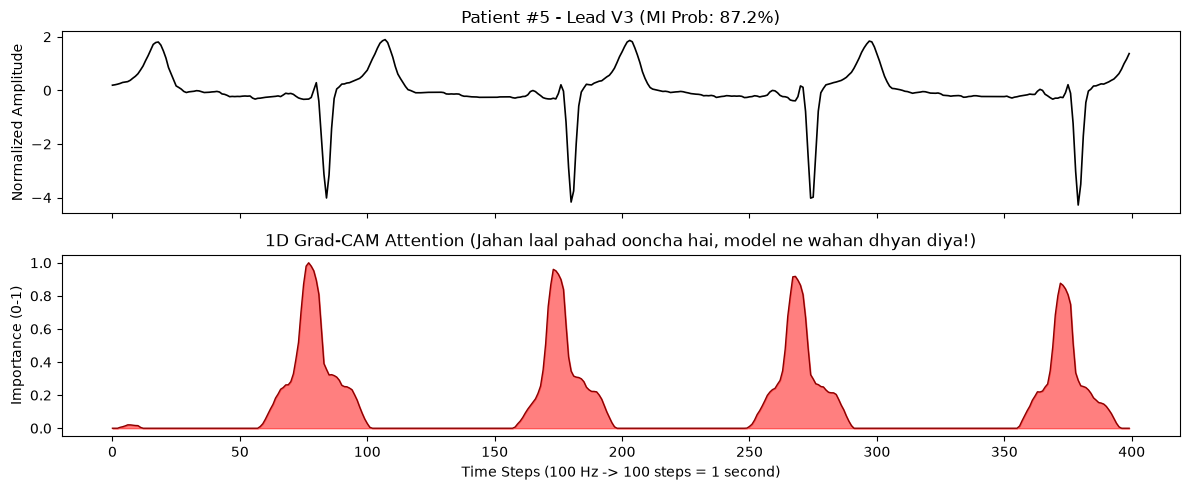

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device('cpu')
lead_names = [
    'I',
    'II',
    'III',
    'aVR',
    'aVL',
    'aVF',
    'V1',
    'V2',
    'V3',
    'V4',
    'V5',
    'V6',
]
classes = ['CD', 'HYP', 'MI', 'NORM', 'STTC']

# ==========================================================
# 1. DATA LOAD & NORMALIZE (PTB-XL Fold 10 Test Set)
# ==========================================================
X_train = np.load('processed_data/X_train.npy')
mean_12 = X_train.mean(axis=(0, 1)).reshape(1, 12, 1)
std_12 = X_train.std(axis=(0, 1)).reshape(1, 12, 1) + 1e-8

X_test = (
    np.transpose(np.load('processed_data/X_test.npy'), (0, 2, 1)) - mean_12
) / std_12
y_test = np.load('processed_data/y_test.npy')


# ==========================================================
# 2. MODEL ARCHITECTURE DEFINE KARO & WEIGHTS LOAD KARO
# ==========================================================
class InceptionModule(nn.Module):

  def __init__(self, in_ch, nf=32, bottleneck=32, ks=(9, 19, 39)):
    super().__init__()
    self.bottleneck = nn.Conv1d(in_ch, bottleneck, 1, bias=False)
    self.convs = nn.ModuleList(
        [nn.Conv1d(bottleneck, nf, k, padding='same', bias=False) for k in ks]
    )
    self.pool_branch = nn.Sequential(
        nn.MaxPool1d(3, stride=1, padding=1),
        nn.Conv1d(in_ch, nf, 1, bias=False),
    )
    self.bn = nn.BatchNorm1d(nf * (len(ks) + 1))

  def forward(self, x):
    z = self.bottleneck(x)
    out = torch.cat([c(z) for c in self.convs] + [self.pool_branch(x)], dim=1)
    return torch.relu(self.bn(out))


class InceptionNet(nn.Module):

  def __init__(self, in_ch=12, n_classes=5, nf=32, depth=6):
    super().__init__()
    out_ch = nf * 4
    self.blocks = nn.ModuleList([
        InceptionModule(in_ch if d == 0 else out_ch, nf) for d in range(depth)
    ])
    self.shortcuts = nn.ModuleList([
        nn.Sequential(
            nn.Conv1d(in_ch if i == 0 else out_ch, out_ch, 1, bias=False),
            nn.BatchNorm1d(out_ch),
        )
        for i in range(depth // 3)
    ])
    self.fc = nn.Linear(out_ch, n_classes)

  def forward(self, x):
    res, r = x, 0
    for d, blk in enumerate(self.blocks):
      x = blk(x)
      if d % 3 == 2:
        x = torch.relu(x + self.shortcuts[r](res))
        res, r = x, r + 1
    return self.fc(x.mean(dim=-1))


model = InceptionNet(n_classes=5).to(device)
model.load_state_dict(torch.load('inception_seed42.pt', map_location=device))
model.eval()
print('Model loaded successfully!')

# ==========================================================
# 3. EK 'MI' (HEART ATTACK) PATIENT UTHAO
# ==========================================================
mi_list = np.flatnonzero(y_test[:, 2] == 1).tolist()
idx = next(iter(mi_list))  # Pehla MI patient (bina index brackets ke!)
x_sample = torch.tensor(
    X_test[idx : idx + 1], dtype=torch.float32
)  # (1, 12, 1000)

probs_all = torch.sigmoid(model(x_sample)).detach().numpy().reshape(-1)
base_prob = float(probs_all[2])
print(f'Patient #{idx} | Original MI Probability: {base_prob*100:.2f}%\n')

# ==========================================================
# 4. XAI METHOD 1: LEAD IMPORTANCE (Kaunsi Lead Sabse Zaroori?)
# ==========================================================
lead_drops = []
with torch.no_grad():
  for l in range(12):
    x_masked = x_sample.clone()
    x_masked[:, l, :] = 0.0
    p_new = float(torch.sigmoid(model(x_masked)).numpy().reshape(-1)[2])
    lead_drops.append(base_prob - p_new)

best_lead = int(np.argmax(lead_drops))
print('Lead-by-Lead MI Probability Drop (zyada drop = zyada important lead):')
for l, drop in enumerate(lead_drops):
  print(f'  {lead_names[l]:3s}: {drop*100:+6.2f}%')

print(f'\n--> Sabse Important Lead: {lead_names[best_lead]}')

# ==========================================================
# 5. XAI METHOD 2: 1D GRAD-CAM (ECG Wave Par Kahan Dekha?)
# ==========================================================
activations, gradients = None, None


def fwd_hook(m, inp, out):
  global activations
  activations = out.detach()


def bwd_hook(m, grad_in, grad_out):
  global gradients
  gradients = grad_out[0].detach()


last_block = list(model.blocks)[-1]
h1 = last_block.register_forward_hook(fwd_hook)
h2 = last_block.register_full_backward_hook(bwd_hook)

out = model(x_sample)
model.zero_grad()
out[0, 2].backward()  # Class 2 ('MI') ke liye gradient
h1.remove()
h2.remove()

weights = gradients.mean(dim=-1, keepdim=True)
cam = F.relu((weights * activations).sum(dim=1)).squeeze().numpy()
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

# Plot: Sabse important lead ka ECG + Grad-CAM highlight!
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
sig = x_sample[0, best_lead, :400].numpy()
heat = cam[:400]

ax1.plot(sig, color='black', lw=1.2)
ax1.set_title(
    f'Patient #{idx} - Lead {lead_names[best_lead]} (MI Prob:'
    f' {base_prob*100:.1f}%)'
)
ax1.set_ylabel('Normalized Amplitude')

ax2.fill_between(range(400), heat, color='red', alpha=0.5)
ax2.plot(heat, color='darkred', lw=1)
ax2.set_title(
    '1D Grad-CAM Attention (Jahan laal pahad ooncha hai, model ne wahan dhyan'
    ' diya!)'
)
ax2.set_ylabel('Importance (0-1)')
ax2.set_xlabel('Time Steps (100 Hz -> 100 steps = 1 second)')
plt.tight_layout()
plt.show()
